In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Common plot style and colours (same colour for the same class everywhere)
sns.set_theme(style="whitegrid", font_scale=1.1)
COLORS = {"Malignant": "#d62728", "Benign": "#2ca02c"}


In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
y_named = y.map({0: "Malignant", 1: "Benign"})   # readable labels for plots

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("\nFirst 5 rows:")
print(X.head())

Dataset shape: (569, 30)
Number of features: 30

First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ..

In [3]:
print("\n--- DATA QUALITY CHECKS ---")
print("Missing values  :", X.isnull().sum().sum())
print("Duplicate rows  :", X.duplicated().sum())

print("\nClass distribution:")
print(y_named.value_counts())

print("\nSummary statistics (first 5 features):")
print(X.iloc[:, :5].describe().round(2))

# Why scaling is needed: features have very different ranges
ranges = (X.max() - X.min()).sort_values(ascending=False)
print("\nLargest feature ranges:")
print(ranges.head(3).round(2))
print("Smallest feature ranges:")
print(ranges.tail(3).round(5))


--- DATA QUALITY CHECKS ---
Missing values  : 0
Duplicate rows  : 0

Class distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64

Summary statistics (first 5 features):
       mean radius  mean texture  mean perimeter  mean area  mean smoothness
count       569.00        569.00          569.00     569.00           569.00
mean         14.13         19.29           91.97     654.89             0.10
std           3.52          4.30           24.30     351.91             0.01
min           6.98          9.71           43.79     143.50             0.05
25%          11.70         16.17           75.17     420.30             0.09
50%          13.37         18.84           86.24     551.10             0.10
75%          15.78         21.80          104.10     782.70             0.11
max          28.11         39.28          188.50    2501.00             0.16

Largest feature ranges:
worst area    4068.8
mean area     2357.5
area error     535.4
dtype: float64
Smalles

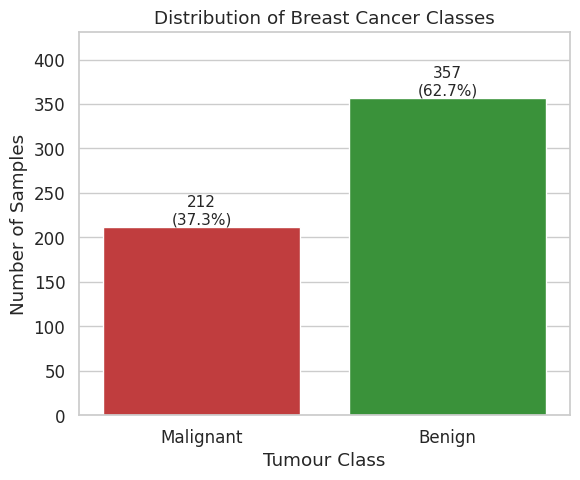

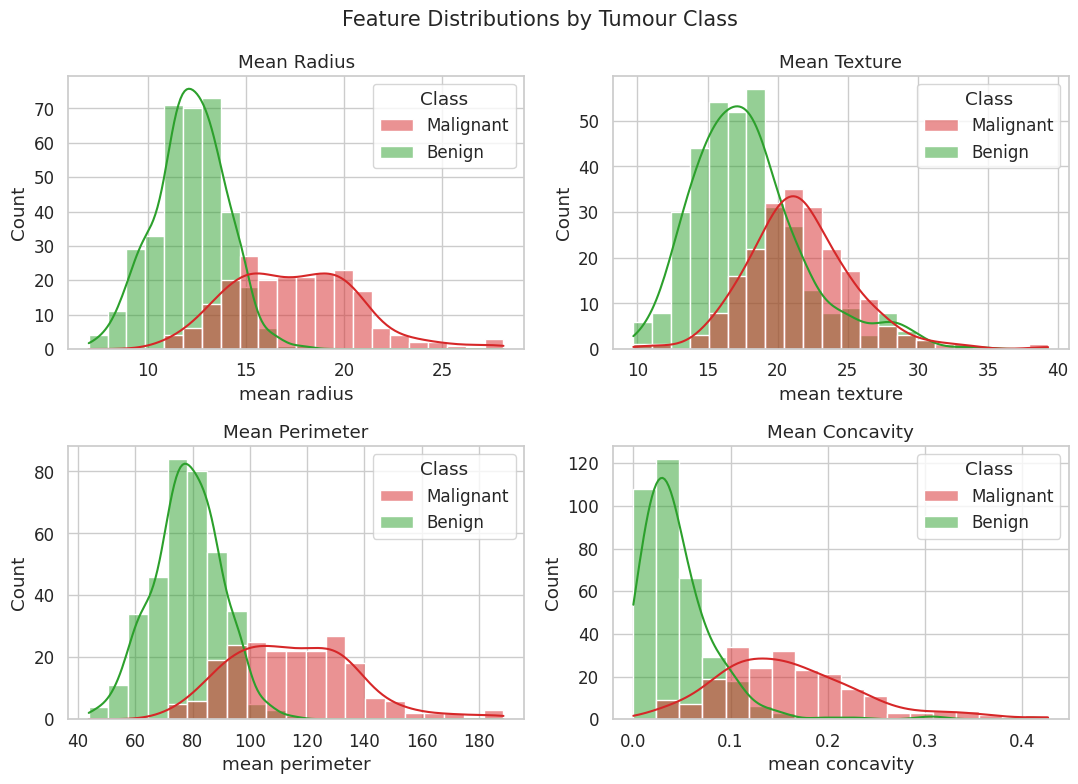

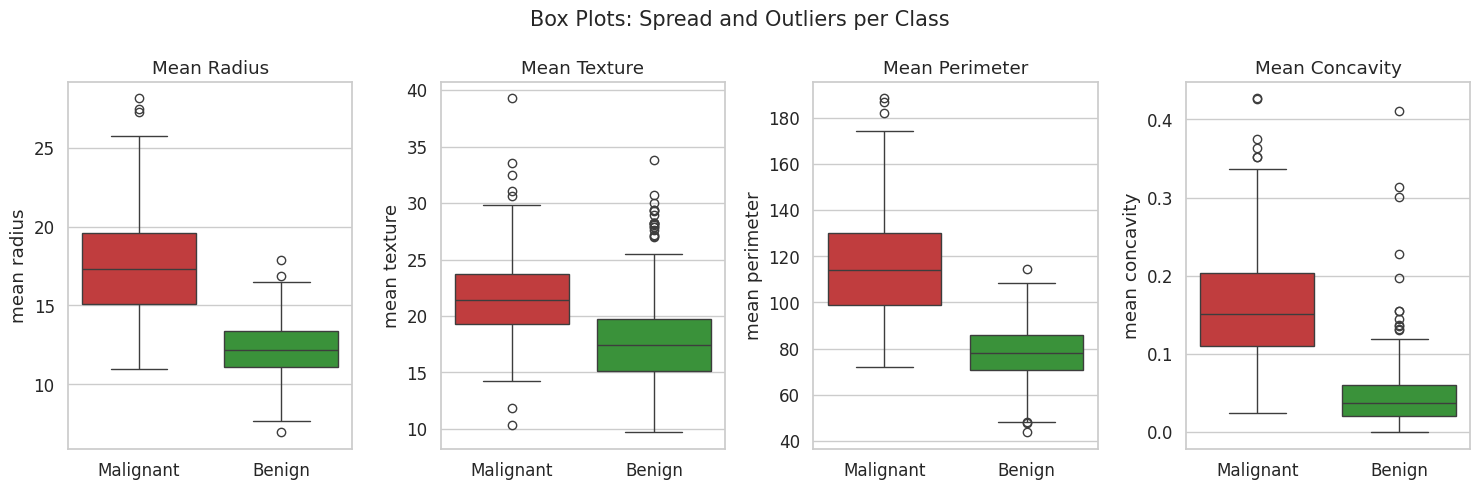

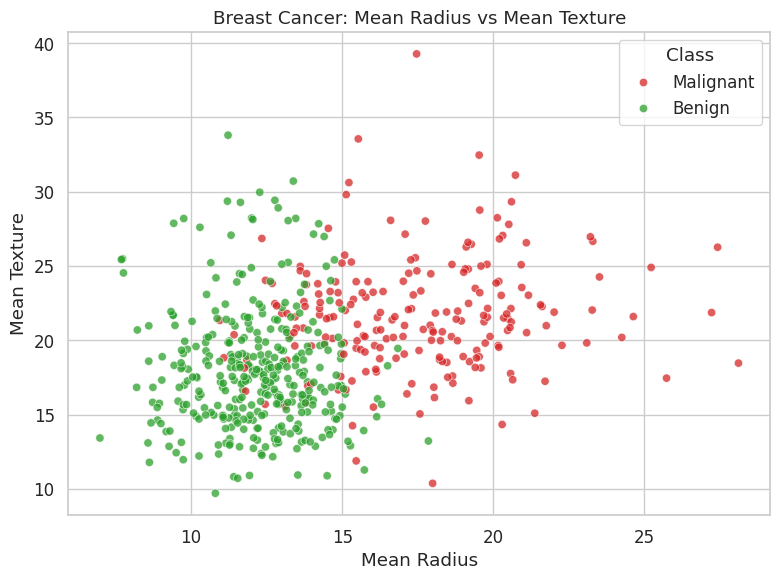

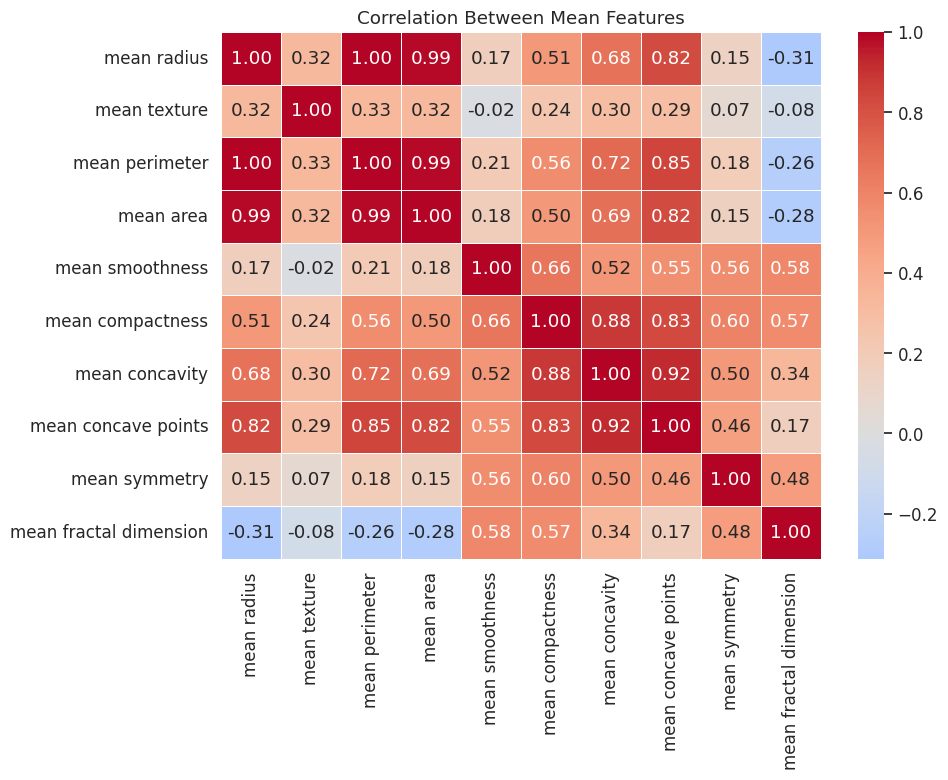

In [4]:
plt.figure(figsize=(6, 5))
ax = sns.countplot(x=y_named, hue=y_named, palette=COLORS,
                   order=["Malignant", "Benign"], legend=False)
total = len(y_named)
for bar in ax.patches:
    h = bar.get_height()
    ax.annotate(f"{int(h)}\n({h / total * 100:.1f}%)",
                (bar.get_x() + bar.get_width() / 2, h),
                ha="center", va="bottom", fontsize=11)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Tumour Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# 3.2 Feature distributions by class (shows which features separate the classes)
key_features = ["mean radius", "mean texture", "mean perimeter", "mean concavity"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feature in zip(axes.ravel(), key_features):
    sns.histplot(data=X.assign(Class=y_named), x=feature, hue="Class",
                 palette=COLORS, kde=True, alpha=0.5, ax=ax)
    ax.set_title(feature.title())
plt.suptitle("Feature Distributions by Tumour Class", fontsize=15)
plt.tight_layout()
plt.show()

# 3.3 Box plots (also reveal outliers)
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
for ax, feature in zip(axes, key_features):
    sns.boxplot(x=y_named, y=X[feature], hue=y_named, palette=COLORS,
                order=["Malignant", "Benign"], legend=False, ax=ax)
    ax.set_title(feature.title())
    ax.set_xlabel("")
plt.suptitle("Box Plots: Spread and Outliers per Class", fontsize=15)
plt.tight_layout()
plt.show()

# 3.4 Scatter plot of two important features
plt.figure(figsize=(8, 6))
sns.scatterplot(data=X, x="mean radius", y="mean texture",
                hue=y_named, palette=COLORS, alpha=0.75, edgecolor="white")
plt.title("Breast Cancer: Mean Radius vs Mean Texture")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

# 3.5 Correlation heatmap (only the 10 'mean' features to keep it readable)
mean_cols = [c for c in X.columns if c.startswith("mean")]
plt.figure(figsize=(10, 8))
sns.heatmap(X[mean_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Between Mean Features")
plt.tight_layout()
plt.show()


Training samples: 455
Testing samples : 114
Train class ratio (benign): 0.626
Test  class ratio (benign): 0.632


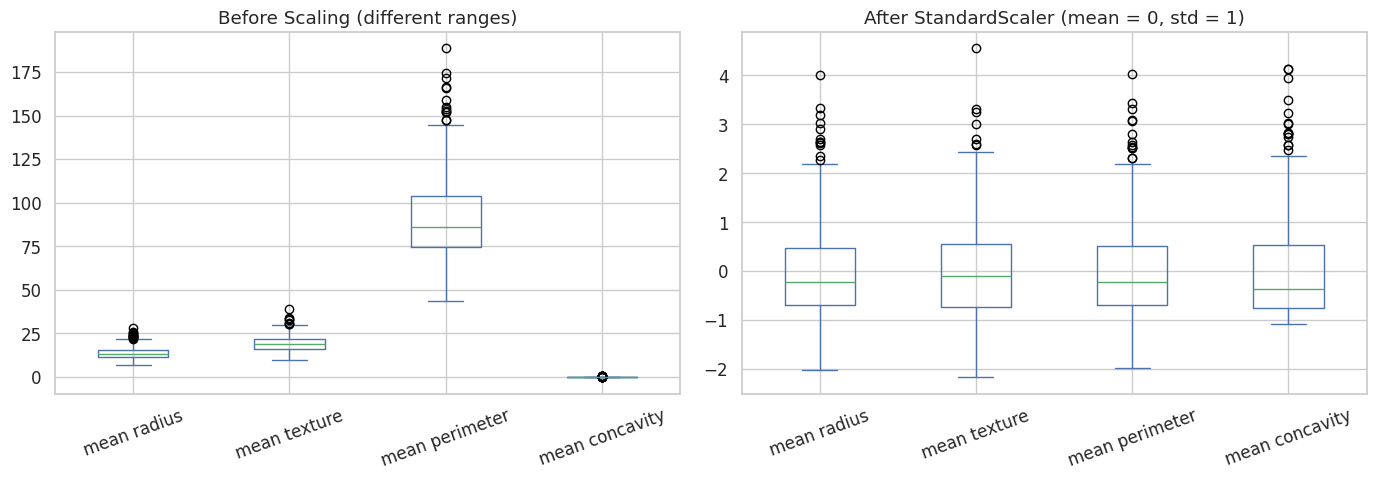

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("\nTraining samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])
print("Train class ratio (benign):", round(y_train.mean(), 3))
print("Test  class ratio (benign):", round(y_test.mean(), 3))

# 4.2 Show the effect of scaling (before vs after)
# The scaler is fitted ONLY on training data to avoid data leakage.
scaler_demo = StandardScaler().fit(X_train)
X_train_scaled = pd.DataFrame(scaler_demo.transform(X_train), columns=X.columns)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
X_train[key_features].plot(kind="box", ax=axes[0])
axes[0].set_title("Before Scaling (different ranges)")
X_train_scaled[key_features].plot(kind="box", ax=axes[1])
axes[1].set_title("After StandardScaler (mean = 0, std = 1)")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# 4.3 Pipeline = imputer -> scaler -> model
# A pipeline applies the same steps to train and test data automatically.
linear_svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),  # fills missing values
    ("scaler", StandardScaler()),                   # puts features on same scale
    ("model", SVC(kernel="linear", class_weight="balanced"))
])

In [6]:
linear_svm.fit(X_train, y_train)
print("\nModel training completed.")


Model training completed.



LINEAR SVM EVALUATION
---------------------
Accuracy : 0.9561
Precision: 0.9855
Recall   : 0.9444
F1-score : 0.9645
ROC-AUC  : 0.9954

Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



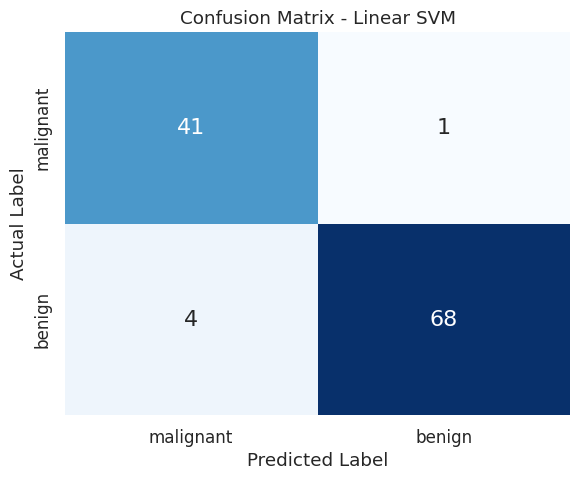

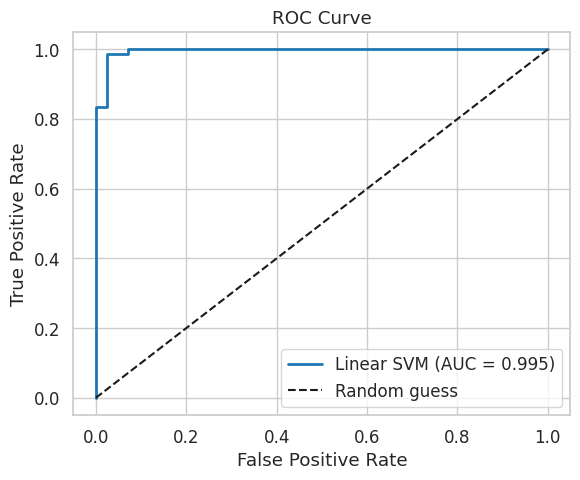

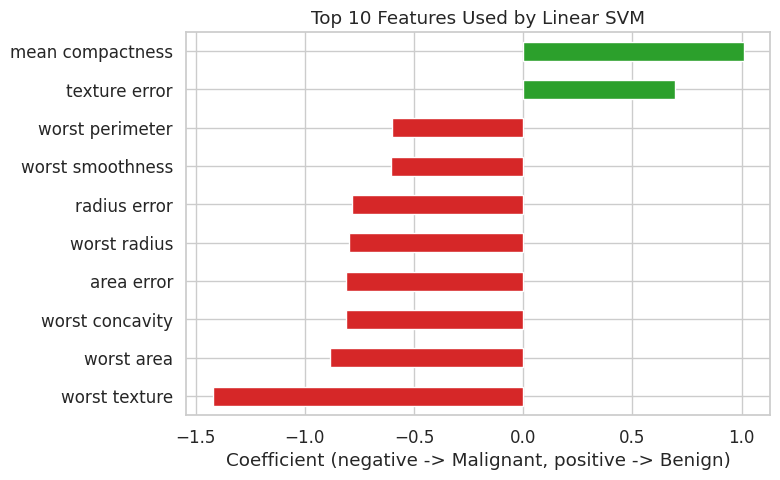

In [7]:
y_pred = linear_svm.predict(X_test)
y_scores = linear_svm.decision_function(X_test)   # distance from the boundary

print("\nLINEAR SVM EVALUATION")
print("---------------------")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_scores), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# 6.1 Confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=data.target_names, yticklabels=data.target_names,
            annot_kws={"size": 16})
plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# 6.2 ROC curve
fpr, tpr, _ = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="#1f77b4", lw=2, label=f"Linear SVM (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 6.3 Top features the model relies on (linear SVM coefficients)
coefs = pd.Series(linear_svm.named_steps["model"].coef_[0], index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).head(10).index)
plt.figure(figsize=(8, 5))
top.sort_values().plot(kind="barh",
                       color=["#d62728" if v < 0 else "#2ca02c" for v in top.sort_values()])
plt.title("Top 10 Features Used by Linear SVM")
plt.xlabel("Coefficient (negative -> Malignant, positive -> Benign)")
plt.tight_layout()
plt.show()


In [ ]:
#non linear

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [10]:
X, y = make_circles(n_samples=400, noise=0.1, factor=0.4, random_state=42)

print("Dataset shape:", X.shape)
print("Class counts:", np.bincount(y))


Dataset shape: (400, 2)
Class counts: [200 200]


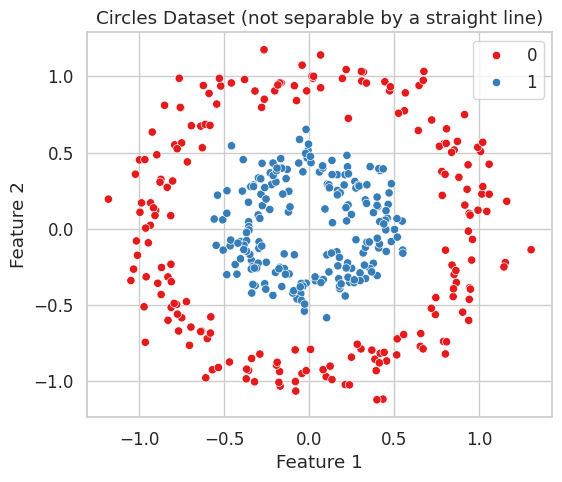

In [11]:
plt.figure(figsize=(6, 5))
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette="Set1")
plt.title("Circles Dataset (not separable by a straight line)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale: learn mean/std from training data, apply the same to test data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [13]:
linear_model = SVC(kernel="linear")
linear_model.fit(X_train_scaled, y_train)

# Non-linear SVM: curved boundary using the RBF kernel
# C     = how strictly we punish misclassified points
# gamma = how far the influence of one point reaches
rbf_model = SVC(kernel="rbf", C=1, gamma="scale")
rbf_model.fit(X_train_scaled, y_train)


SVC(C=1)


Linear SVM accuracy: 0.55
RBF SVM accuracy   : 1.0

RBF SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00        40

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



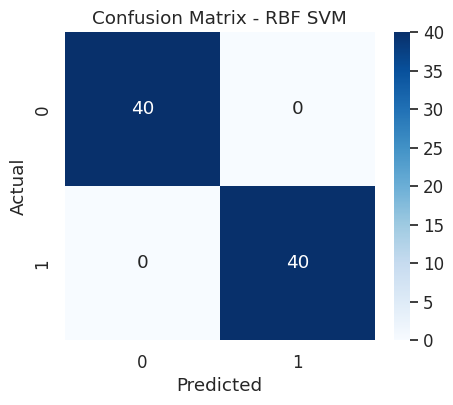

In [14]:
linear_pred = linear_model.predict(X_test_scaled)
rbf_pred = rbf_model.predict(X_test_scaled)

print("\nLinear SVM accuracy:", round(accuracy_score(y_test, linear_pred), 4))
print("RBF SVM accuracy   :", round(accuracy_score(y_test, rbf_pred), 4))

print("\nRBF SVM Classification Report:")
print(classification_report(y_test, rbf_pred))

# Confusion matrix of the RBF model
cm = confusion_matrix(y_test, rbf_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - RBF SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


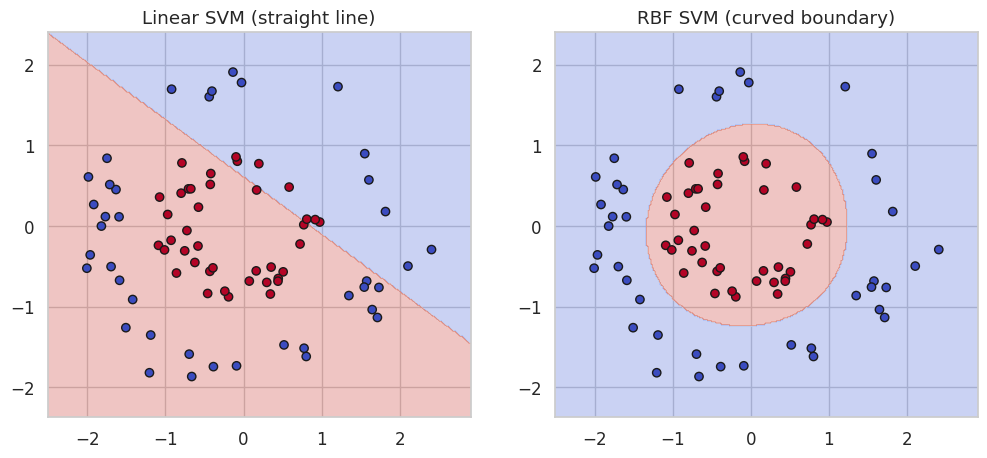

In [15]:
def plot_boundary(model, X_data, y_data, title, ax):
    # Make a grid of points covering the whole plot area
    x_min, x_max = X_data[:, 0].min() - 0.5, X_data[:, 0].max() + 0.5
    y_min, y_max = X_data[:, 1].min() - 0.5, X_data[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))

    # Ask the model to predict the class of every grid point
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Colour the regions, then draw the real data points on top
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_data[:, 0], X_data[:, 1], c=y_data, cmap="coolwarm", edgecolor="k")
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_boundary(linear_model, X_test_scaled, y_test, "Linear SVM (straight line)", axes[0])
plot_boundary(rbf_model, X_test_scaled, y_test, "RBF SVM (curved boundary)", axes[1])
plt.show()